# Import Libraries

In [56]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import grangercausalitytests

# Download Financial Data

Download 5 years of USD Index. Columns Volume, Dividends and Stock Splits are not required, since they are constant and equal to 0.0

In [57]:
ticker_symbol = 'DX-Y.NYB'

ticker = yf.Ticker(ticker_symbol)
df = ticker.history(period='5y').drop(columns=['Volume', 'Dividends', 'Stock Splits']).reset_index(drop=False)
df

,Date,Open,High,Low,Close
0,2021-10-25 00:00:00-04:00,93.660004,93.959999,93.480003,93.809998
1,2021-10-26 00:00:00-04:00,93.839996,94.019997,93.709999,93.949997
2,2021-10-27 00:00:00-04:00,93.970001,94.010002,93.690002,93.860001
3,2021-10-28 00:00:00-04:00,93.879997,93.970001,93.279999,93.349998
4,2021-10-29 00:00:00-04:00,93.360001,94.300003,93.320000,94.120003
...,...,...,...,...,...
1252,2026-10-19 00:00:00-04:00,102.010002,102.080002,101.769997,101.980003
1253,2026-10-20 00:00:00-04:00,101.980003,101.980003,101.510002,101.730003
1254,2026-10-21 00:00:00-04:00,101.779999,101.839996,101.639999,101.779999
1255,2026-10-22 00:00:00-04:00,101.709999,101.879997,101.449997,101.610001


# Construct Line Plot of HLC Data

In [3]:
fig = px.line(df, x='Date', y=['High', 'Close', 'Low'], title='USD Price Index from 2021 to 2026')
fig.show()

# Train-Test Split

Test set should start 1 time step after the end of train set.

In [4]:
train_size = 0.7
history_size = 30

num_train_samples = int(df.shape[0]*train_size)
train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples - history_size:]

train_df.shape, test_df.shape

((879, 5), (408, 5))

# Construct Timeframes

*   x = <x[0], x[1], x[2], ... x[H-1]>
*   y = x[H]

where x is (Open(t), High(t), Low(t), Close(t))

**Important: Past target must be included in x to achieve good accuracy**

In [5]:
def construct_timeframes(df, H):
    inputs = df.drop(columns=['Date']).to_numpy(dtype=np.float64)
    x = np.array([inputs[i-H: i].flatten() for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

# Verify Timeframes

In [6]:
train_df.head(5)

,Date,Open,High,Low,Close
0,2021-10-25 00:00:00-04:00,93.660004,93.959999,93.480003,93.809998
1,2021-10-26 00:00:00-04:00,93.839996,94.019997,93.709999,93.949997
2,2021-10-27 00:00:00-04:00,93.970001,94.010002,93.690002,93.860001
3,2021-10-28 00:00:00-04:00,93.879997,93.970001,93.279999,93.349998
4,2021-10-29 00:00:00-04:00,93.360001,94.300003,93.320000,94.120003


In [8]:
x_train, y_train = construct_timeframes(train_df, H=4)
print('x:', x_train[0],'\ny:', y_train[0])

x: [93.66000366 93.95999908 93.48000336 93.80999756 93.83999634 94.01999664
 93.70999908 93.94999695 93.97000122 94.01000214 93.69000244 93.86000061
 93.87999725 93.97000122 93.27999878 93.34999847] 
y: 94.12000274658203


# Fit Linear Regression Model

Setting H = 30

In [9]:
x_train, y_train = construct_timeframes(train_df, history_size)
x_test, y_test = construct_timeframes(test_df, history_size)

x_train.shape, y_train.shape, x_test.shape, y_test.shape

((849, 120), (849,), (378, 120), (378,))

<Axes: title={'center': 'Train-Test MAE of Linear Regression with H=30'}, xlabel='Dataset', ylabel='MAE'>

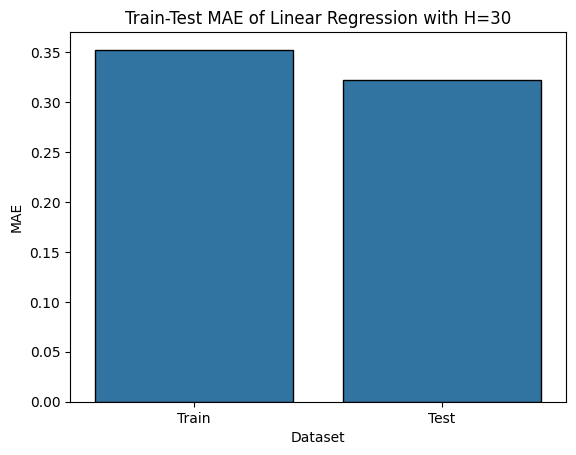

In [10]:
model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_train)
train_mae = mean_absolute_error(y_true=y_train, y_pred=y_pred)
y_pred = model.predict(x_test)
test_mae = mean_absolute_error(y_true=y_test, y_pred=y_pred)

metrics_df = pd.DataFrame({'Dataset': ['Train', 'Test'], 'MAE': [train_mae, test_mae]})
ax = sns.barplot(metrics_df, x='Dataset', y='MAE', edgecolor='black')
ax.set_title('Train-Test MAE of Linear Regression with H=30')
ax

# Visualize Predictions

In [28]:
train_dates = train_df['Date'].iloc[history_size:]
test_dates = test_df['Date'].iloc[history_size:]

# Create figure
fig = go.Figure()

# Training data (last history_size samples only)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_train)[-history_size:],
    mode='lines',
    name='Train',
    line=dict(color='royalblue', width=2)
))

# Test actual values
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_test),
    mode='lines',
    name='Test (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))

# Vertical dashed line separating train/test
fig.add_shape(
    type='line',
    x0=test_dates.iloc[0],
    x1=test_dates.iloc[0],
    y0=0,
    y1=1,
    xref='x',
    yref='paper',
    line=dict(color='black', width=2, dash='dash')
)

# Prediction line for test set
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_pred),
    mode='lines',
    name='Test (Predicted)',
    line=dict(color='#E63946', width=2.5)
))

# Layout
fig.update_layout(
    title='USD Price Index — Close Price Prediction',
    xaxis_title='Date',
    yaxis_title='Price ($)',
    template='plotly_white',
    legend=dict(x=0.01, y=0.99),
    hovermode='x unified'
)

fig.show()

# Apply Log Returns Transformation

In [29]:
vars = ['Open', 'High', 'Low', 'Close']
df_logr = df.copy()
df_logr[vars] = np.log(df_logr[vars]/df_logr[vars].shift(1))
df_logr

,Date,Open,High,Low,Close
0,2021-10-25 00:00:00-04:00,NaN,NaN,NaN,NaN
1,2021-10-26 00:00:00-04:00,0.001920,0.000638,0.002457,0.001491
2,2021-10-27 00:00:00-04:00,0.001384,-0.000106,-0.000213,-0.000958
3,2021-10-28 00:00:00-04:00,-0.000958,-0.000426,-0.004386,-0.005448
4,2021-10-29 00:00:00-04:00,-0.005554,0.003506,0.000429,0.008215
...,...,...,...,...,...
1252,2026-10-19 00:00:00-04:00,-0.000294,-0.000098,0.001869,0.001374
1253,2026-10-20 00:00:00-04:00,-0.000294,-0.000980,-0.002558,-0.002454
1254,2026-10-21 00:00:00-04:00,-0.001963,-0.001374,0.001280,0.000491
1255,2026-10-22 00:00:00-04:00,-0.000688,0.000393,-0.001871,-0.001672


# Convert Log Returns to Absolute Price

$lr_{t+1} = \ln(\frac{y_{t+1}}{y_{t}})$

$y_{t+1} = y_t * e^{lr_{t+1}}$

Inevitably, the first sample will be lost, as its log-return transformation cannot be defined (x[-1] does not exist).

In [30]:
def log_returns_to_absolute_prices(prices, log_returns):
    return prices * np.exp(log_returns)

In [31]:
valid_df = pd.DataFrame({
    'Date': df['Date'].iloc[: 6],
    'Close': df['Close'].iloc[: 6],
    'CLose-Log-Returns': df_logr['Close'].iloc[: 6]
})
valid_df

,Date,Close,CLose-Log-Returns
0,2021-10-25 00:00:00-04:00,93.809998,NaN
1,2021-10-26 00:00:00-04:00,93.949997,0.001491
2,2021-10-27 00:00:00-04:00,93.860001,-0.000958
3,2021-10-28 00:00:00-04:00,93.349998,-0.005448
4,2021-10-29 00:00:00-04:00,94.120003,0.008215
5,2021-11-01 00:00:00-04:00,93.879997,-0.002553


In [32]:
log_returns_to_absolute_prices(
    prices=valid_df['Close'].iloc[: -1].to_numpy(),
    log_returns=valid_df['CLose-Log-Returns'].iloc[1:].to_numpy()
)

array([93.94999695, 93.86000061, 93.34999847, 94.12000275, 93.87999725])

# Check Whether High can Predict Close

Variables that can estimate the target variable are considered beneficial.

In [64]:
data = train_df[['Close', 'Open']]

# Computing log-returns (converting to stationary series).
data = np.log(data/data.shift(1)).dropna()

# Test up to history_size lags
results = grangercausalitytests(data[['Close', 'Open']], maxlag=history_size)

# Extract p-values
p_values = {
    lag: results[lag][0]['ssr_ftest'][1]
    for lag in range(1, history_size + 1)
}
results_df = pd.DataFrame({'Lag (H)': list(p_values.keys()), 'P-value': list(p_values.values())})
results_df['Significant'] = results_df['P-value'] < 0.05
results_df

,Lag (H),P-value,Significant
0,1,0.006519,True
1,2,0.805271,False
2,3,0.295929,False
3,4,0.845233,False
4,5,0.604675,False
5,6,0.854056,False
6,7,0.902711,False
7,8,0.686586,False
8,9,0.784308,False
9,10,0.751854,False


# Extracting Temporal Features

In [60]:
# Calendar features
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek  # Monday=0, Sunday=6

# US & NYSE holidays
us_holidays = holidays.country_holidays('US')
nyse_holidays = holidays.financial_holidays('NYSE')

# Global events
global_events = {
    'NewYearsDay': (1, 1),
    'ValentinesDay': (2, 14),
    'WomensDay': (3, 8),
    'AprilFools': (4, 1),
    'EarthDay': (4, 22),
    'LabourDay': (5, 1),
    'EnvironmentDay': (6, 5),
    'Halloween': (10, 31),
    'ChristmasEve': (12, 24),
    'ChristmasDay': (12, 25),
    'BoxingDay': (12, 26),
    'NewYearsEve': (12, 31),
}

event_dates = set(global_events.values())

# Combine US holidays, NYSE holidays, and global events
df['IsHoliday'] = df['Date'].dt.date.map(
    lambda d: int(
        d in us_holidays
        or d in nyse_holidays
        or (d.month, d.day) in event_dates
    )
)

df

,Date,Open,High,Low,Close,Month,DayOfWeek,IsHoliday
0,2021-10-25 00:00:00-04:00,93.660004,93.959999,93.480003,93.809998,10,0,0
1,2021-10-26 00:00:00-04:00,93.839996,94.019997,93.709999,93.949997,10,1,0
2,2021-10-27 00:00:00-04:00,93.970001,94.010002,93.690002,93.860001,10,2,0
3,2021-10-28 00:00:00-04:00,93.879997,93.970001,93.279999,93.349998,10,3,0
4,2021-10-29 00:00:00-04:00,93.360001,94.300003,93.320000,94.120003,10,4,0
...,...,...,...,...,...,...,...,...
1252,2026-10-19 00:00:00-04:00,102.010002,102.080002,101.769997,101.980003,10,0,0
1253,2026-10-20 00:00:00-04:00,101.980003,101.980003,101.510002,101.730003,10,1,0
1254,2026-10-21 00:00:00-04:00,101.779999,101.839996,101.639999,101.779999,10,2,0
1255,2026-10-22 00:00:00-04:00,101.709999,101.879997,101.449997,101.610001,10,3,0


In [61]:
df['IsHoliday'].value_counts()

,count
IsHoliday,
0,1210
1,47
